In [18]:
# ---------------------------------------------------------------------------
# 0. Import Libraries and Reproducibility setup
# ---------------------------------------------------------------------------
import os
import sys
import numpy
import scipy
import matplotlib
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize
matplotlib.get_backend()

SEED = 42                                                 # Random seed 
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ---------------------------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------------------------
X = np.load('..\Function_2_Data\Week_9_Data/F2_Week_9_inputs.npy')
y = np.load('..\Function_2_Data\Week_9_Data/F2_Week_9_outputs.npy')
n_round1 = 16
n, d = X.shape
print(f"n_samples={n}, n_dims={d}")

n_samples=18, n_dims=2


In [20]:
# ---------------------------------------------------------------------------
# 2. Data transformation
# ---------------------------------------------------------------------------
# Inputs already live in [0,1] x [0,1] -- no rescaling needed.
bounds = np.array([[0.0, 1.0], [0.0, 1.0]])

# Standardize y: 
y_mean, y_std = y.mean(), y.std()
y_scaled = (y - y_mean) / y_std

def unscale_y(y_s):
    return y_s * y_std + y_mean      #  Map standardized y back to original units.

In [21]:
# ---------------------------------------------------------------------------
# 3. Surrogate model: GP with Matern 5/2, ARD length scales + WhiteKernel
# ---------------------------------------------------------------------------

kernel = (
    ConstantKernel(1.0, constant_value_bounds=(1e-3, 1e3))
    * Matern(length_scale=[0.3, 0.3],
             length_scale_bounds=(1e-2, 1.0),   # <-- tightened upper bound (was 2.0)
             nu=2.5)
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e-1))
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=20,   
    normalize_y=False,         # already standardized y
    random_state=SEED,
)
gp.fit(X, y_scaled)

print("\nFitted kernel:", gp.kernel_)
print("Log-marginal-likelihood:", gp.log_marginal_likelihood_value_)


Fitted kernel: 0.992**2 * Matern(length_scale=[0.0628, 1], nu=2.5) + WhiteKernel(noise_level=0.0431)
Log-marginal-likelihood: -15.682246534955759


C:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [22]:
# ---------------------------------------------------------------------------
# 4. Acquisition function: Expected Improvement (EI)
# ---------------------------------------------------------------------------

def expected_improvement(X_cand, gp, y_best, xi):
    """
    Vectorized EI for maximization.
    X_cand: (m, d) candidate points
    y_best: best observed value so far (standardized scale)
    xi: exploration jitter (standardized y units) -- larger favors
        exploration, smaller favors exploitation.
    """
    mu, sigma = gp.predict(X_cand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    imp = mu - y_best - xi
    z = imp / sigma
    ei = imp * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

y_best = y_scaled.max()
best_idx = np.argmax(y_scaled)
print(f"\nBest observed point so far: x={X[best_idx]}, y={y[best_idx]:.4f}")

def optimize_ei(gp, y_best, xi, bounds, n_restarts=50, rng=rng):
    
    def neg_ei(x):
        return -expected_improvement(x.reshape(1, -1), gp, y_best, xi)[0]

    best_x, best_val = None, np.inf
    starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(n_restarts, d))
    for x0 in starts:
        res = minimize(neg_ei, x0, bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val, best_x = res.fun, res.x
    return best_x, -best_val


Best observed point so far: x=[0.704881 0.      ], y=0.6951


In [23]:
CONFIRM_POINT = np.array([0.70, 0.40])  # fixed diagnostic probe, not optimized
mu_a, std_a = gp.predict(CONFIRM_POINT.reshape(1, -1), return_std=True)

XI_NEXT = 0.01
x_next, ei_next = optimize_ei(gp, y_best, XI_NEXT, bounds)
mu_b, std_b = gp.predict(x_next.reshape(1, -1), return_std=True)

suggestions = [
    {"round": f"(EI argmax, xi={XI_NEXT})", "x": x_next,
     "pred_mean": unscale_y(mu_b[0]), "pred_std": std_b[0] * y_std,
     "purpose": f"standard next-point with EI={ei_next:.5f}"},
]

print("\nConcrete suggestions from THIS round's data (A and B):")
for s in suggestions:
    print(f"  [{s['round']:>6}] x=({s['x'][0]:.6f}, {s['x'][1]:.6f})  "
          f"pred_mean={s['pred_mean']:.4f}  pred_std={s['pred_std']:.4f}  -- {s['purpose']}")




Concrete suggestions from THIS round's data (A and B):
  [(EI argmax, xi=0.01)] x=(0.724011, 0.000000)  pred_mean=0.6301  pred_std=0.0975  -- standard next-point with EI=0.05609


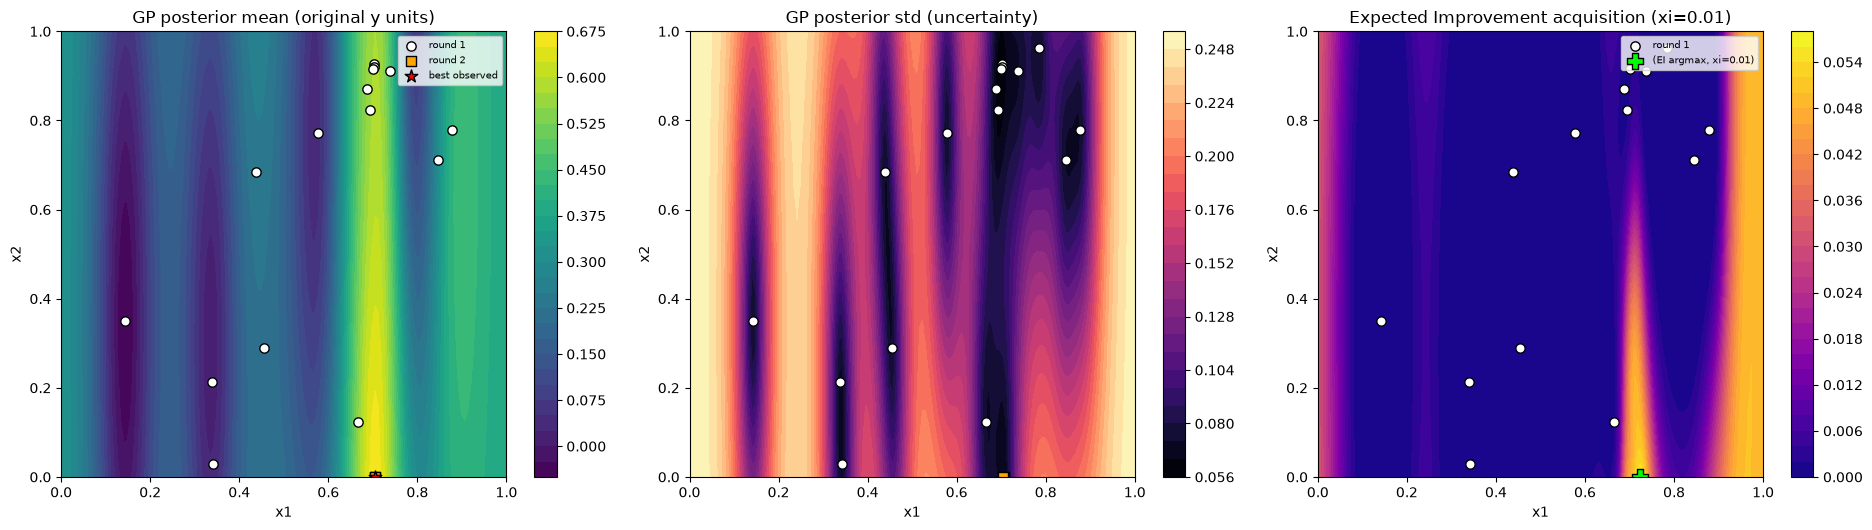

In [24]:
# ---------------------------------------------------------------------------
# 6. Plots
# ---------------------------------------------------------------------------
grid_n = 150
gx = np.linspace(0, 1, grid_n)
gy = np.linspace(0, 1, grid_n)
GX, GY = np.meshgrid(gx, gy)
grid_pts = np.column_stack([GX.ravel(), GY.ravel()])

mu_grid, std_grid = gp.predict(grid_pts, return_std=True)
mu_grid_orig = unscale_y(mu_grid).reshape(grid_n, grid_n)
std_grid_orig = (std_grid * y_std).reshape(grid_n, grid_n)
ei_grid = expected_improvement(grid_pts, gp, y_best, xi=0.01).reshape(grid_n, grid_n)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))

marker_colors = {suggestions[0]["round"]: "lime"}
marker_shapes = {suggestions[0]["round"]: "P"}

# (a) Posterior mean
im0 = axes[0].contourf(GX, GY, mu_grid_orig, levels=30, cmap="viridis")
axes[0].scatter(X[:n_round1, 0], X[:n_round1, 1], c="white", edgecolor="black", s=45, label="round 1")
axes[0].scatter(X[n_round1:, 0], X[n_round1:, 1], c="orange", edgecolor="black", s=60, marker="s", label="round 2")
axes[0].scatter(*X[best_idx], c="red", edgecolor="black", s=90, marker="*", label="best observed")
axes[0].set_title("GP posterior mean (original y units)")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
fig.colorbar(im0, ax=axes[0])
axes[0].legend(loc="upper right", fontsize=7)

# (b) Posterior std (uncertainty)
im1 = axes[1].contourf(GX, GY, std_grid_orig, levels=30, cmap="magma")
axes[1].scatter(X[:n_round1, 0], X[:n_round1, 1], c="white", edgecolor="black", s=45)
axes[1].scatter(X[n_round1:, 0], X[n_round1:, 1], c="orange", edgecolor="black", s=60, marker="s")
axes[1].set_title("GP posterior std (uncertainty)")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2")
fig.colorbar(im1, ax=axes[1])

# (c) Expected Improvement (xi=0.01) + the 4 staged suggestions
im2 = axes[2].contourf(GX, GY, ei_grid, levels=30, cmap="plasma")
axes[2].scatter(X[:n_round1, 0], X[:n_round1, 1], c="white", edgecolor="black", s=45, label="round 1")
for s in suggestions:
    axes[2].scatter(*s["x"], c=marker_colors[s["round"]], edgecolor="black", s=130,
                     marker=marker_shapes[s["round"]], label=s["round"])
axes[2].set_title("Expected Improvement acquisition (xi=0.01)")
axes[2].set_xlabel("x1"); axes[2].set_ylabel("x2")
fig.colorbar(im2, ax=axes[2])
axes[2].legend(loc="upper right", fontsize=7)
plt.tight_layout()